# Chart construction for waypoint Atlas-DeePC: spectral clustering and UMAP

This selected-method report uses the existing **100 exploratory seeds, 211–310**, for spectral clustering and UMAP + K-means. The historical filename retains `500` for existing links. No fitting or control experiments are rerun. The full seven-method report is preserved under `experiments/routed_deepc_iid/clustering_methods_100_clarabel_v1/seven_method_report_archive/`; all original experiment artifacts remain intact.

The baseline is the waypoint method in `notebooks/baselines/baseline_graph_routed_atlas_deepc.ipynb`: **Clarabel, λg=0.05, 48 charts, rank-60 uncentered linear behavioral bases, iterative N=10 terminal references, and graph waypoints**. Q/R, constraints, initialization, horizon, and all 320 control steps are unchanged. Every method uses the same immutable 144×37,800 Hankel matrix, retaining every column in its original order. There is no data recollection, filtering, added noise, fitted dynamics, rescue, expert data, nonlinear decoder, or early termination.

The gate inputs are the six periodic joint-configuration channels of the latest past output, standardized by the baseline mean/std. The four input-history channels have zero weight. Controller bases are constructed only from original full input-output columns. Cluster/embedding dimensions below are unrelated to controller rank 60.

## Fixed choices made before evaluation

| Method | Offline construction | Online assignment |
|---|---|---|
| Spectral | Sparse symmetric 20-neighbor RBF graph, bandwidth=median twentieth-neighbor distance, top48 normalized-adjacency eigenvectors, row normalization and K-means | Nyström eigenfunction extension and the same embedding K-means |
| UMAP | umap-learn, 20 neighbors, four dimensions, min_dist .1, 200 epochs, fit/transform seed11, then K-means | Native `UMAP.transform` per point and embedding K-means |

Both methods share **1,500 uniformly sampled offline landmark indices, seed1701**. All original columns are assigned using the fitted extension; controller data are never reduced to landmarks. Exact fitted landmarks use their saved in-sample coordinates. UMAP transformation is deliberately called per point both offline and online, so its random-seeded transformation does not change with batch composition. Embedding K-means has 10 initializations, seed11, max300. The spectral eigensolver uses a fixed starting vector and deterministic eigenvector signs. Spectral clustering is graph-based clustering; UMAP learns a four-dimensional representation before K-means. The 48-dimensional spectral representation is distinct from the 48 chart labels and the rank-60 controller basis.

Every method rebuilds medoids and within-episode directed transition counts. Medoids are actual members nearest the chart center in the baseline standardized physical features (original gate centroids for K-means, member means otherwise); medoid joint velocities are zeroed. Routing edge cost remains baseline feature RMS distance divided by square-root transition count, threshold3. Nonlinear embedding distance is never used for routing. Empty charts, supports below61, behavioral numerical rank below60, disconnected graphs, fitting nonconvergence, and runtime errors are explicitly reported. There is no chart repair, rank reduction, artificial graph bridge, or replacement controller. An unreachable terminal chart retains the original exception; unsolved QPs retain the original zero-action behavior.

## Timing, artifacts, and interpretation

The saved rollouts were measured in the original seven-method experiment with one worker and one numerical thread, rotating method order within each seed. This notebook selects two methods from that completed experiment. Offline fit/atlas and behavioral-cache construction are separate. The recorded fit/atlas timer includes full-column assignments and initial model/parameter writes; it is not pure optimizer time. Numerical-rank diagnostics and later artifact writes are outside both reported offline timers. UMAP's first fit includes compilation overhead. Each method received a discarded 10-step seed210 warmup. All 320 per-step timers are saved; summaries omit the first5 steps per rollout. Chart-localization time includes the method's out-of-sample extension. QP time includes problem construction and solving. Measurements are wall-clock times on a shared computer.

Each method folder saves original-column memberships, preprocessing, fitted gate/model and coordinates, landmark indices, medoids, transition graph, all 48 behavioral bases/singular values/bounds/ranks, provenance/hashes, full rollouts and timings. Atlases reload without reclustering. Failure artifacts are retained. Baseline outcomes are recomputed; historical timing is not reused.

Strict success requires BOTH final30 and final100 windows to have mean error <10 mm and maximum <20 mm. Error summaries use each rollout's final-100 mean, including unsuccessful rollouts. The seed panel has been used for earlier studies and is **exploratory**, not untouched validation. Hyperparameters were fixed before evaluation; these two methods were selected for presentation after inspecting the broader comparison. The paired test below is descriptive and unadjusted.

Primary references: [spectral clustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html), [UMAP out-of-sample transform](https://umap-learn.readthedocs.io/en/latest/transform.html). Installed package versions are recorded below. The pose grids use the same physical geometry and drawing style as the baseline notebook.


In [1]:
RUN_EXPERIMENTS = False
from pathlib import Path
import json, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display
ROOT = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/clustering_methods_experiment.py').exists())
sys.path.insert(0,str(ROOT/'src'))
import clustering_methods_experiment as experiment
R = experiment.RESULT
summary = json.loads((R/'summary.json').read_text())
assert summary['complete'], 'Experiment is still running; no final report yet.'
assert summary['signature'] == experiment.signature()
assert summary['signature']['seeds'] == list(range(211,311))
assert summary['data_hash_final'] == summary['signature']['data_sha256']
METHODS = {m:experiment.METHODS[m] for m in ('spectral','umap')}
order = list(METHODS)
panels = {m:summary['panels'][m] for m in order}
frames = {}
for method,panel in panels.items():
    checked = [experiment.validate(R/method/f"seed{r['seed']}.npz",method,r['seed'],summary['signature']) for r in panel['results']]
    assert checked == panel['results']
    meta = panel['offline']
    assert meta['data_sha256'] == summary['data_hash_final']
    for name,digest in meta['files'].items():
        assert experiment.file_digest(R/method/name) == digest
    if checked:
        frames[method]=pd.DataFrame(checked).set_index('seed').sort_index()
for method,frame in frames.items():
    assert frame.index.tolist()==list(range(211,311))
    np.testing.assert_array_equal(frames['spectral'].exact_target_xy.tolist(),frame.exact_target_xy.tolist())
REPORT=R/'spectral_umap_report'; REPORT.mkdir(exist_ok=True)
F=REPORT/'figures'; F.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':125,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
colors=dict(zip(order,plt.get_cmap('tab10').colors[:7]))
def save(name):
    plt.tight_layout()
    plt.savefig(F/(name+'.png'),bbox_inches='tight')
    plt.show()
display(pd.Series(summary['signature']['versions'],name='Installed version'))
print('Dataset SHA-256:',summary['data_hash_final'])
print('Validated selected-method rollouts:',sum(len(f) for f in frames.values()),'/200')


numpy                1.26.4
scipy                1.13.1
scikit-learn          1.7.2
cvxpy                 1.6.5
clarabel             0.11.1
gymnasium             1.2.3
mujoco               3.12.0
umap-learn      0.5.9.post2
pynndescent          0.5.13
numba                0.66.0
joblib                1.5.3
Name: Installed version, dtype: object

Dataset SHA-256: 75c6e2e8376c00ac1fc032ecaaa31b9a3eb830b671f68a18e559b22f9263c45b
Validated selected-method rollouts: 200 /200


## Success and final-100 tracking error

,label,completed,successes,success_pct,CI_low,CI_high,median_error_mm,P90_error_mm,unsolved_QPs,trial_errors
method,,,,,,,,,,
spectral,Spectral clustering,100,90,90.0,82.563,94.477,2.063,8.997,0,0
umap,UMAP + K-means,100,92,92.0,85.002,95.891,2.089,5.571,0,0


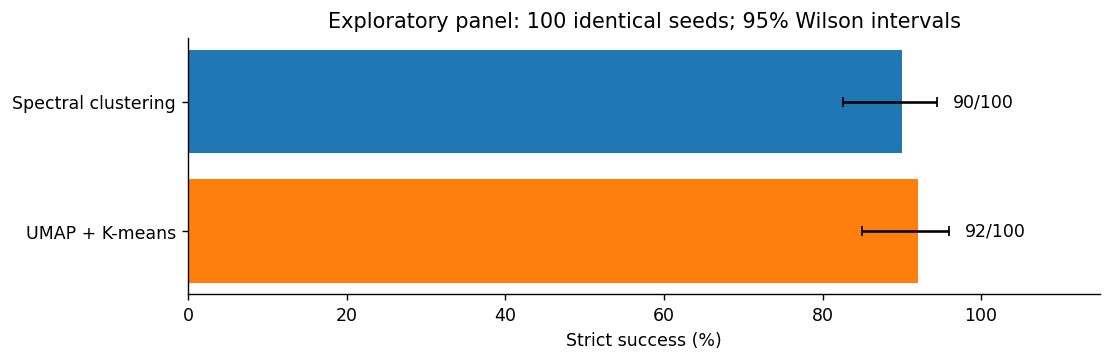

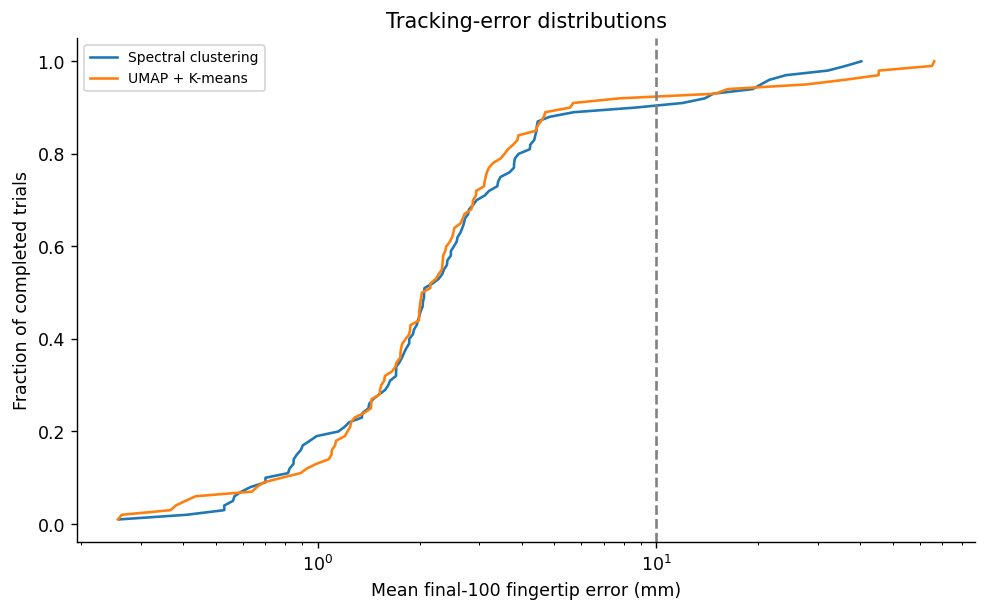

In [2]:
def wilson(k,n):
    z=1.959963984540054; p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return 100*(center-half),100*(center+half)
records=[]
for method in order:
    p=panels.get(method)
    if p and len(p['results']):
        frame=frames[method]; k=p['successes']; n=len(frame)
        low,high=wilson(k,n)
        records.append({'method':method,'label':METHODS[method]['label'],'completed':n,'successes':k,
            'success_pct':100*k/n if n==100 else np.nan,'CI_low':low,'CI_high':high,
            'median_error_mm':1000*frame.mean_last_100.median(),'P90_error_mm':1000*frame.mean_last_100.quantile(.9),
            'unsolved_QPs':int(frame.unsolved_steps.sum()),'trial_errors':len(p['trial_failures'])})
    else:
        records.append({'method':method,'label':METHODS[method]['label'],'completed':0,'successes':0,
            'success_pct':np.nan,'CI_low':np.nan,'CI_high':np.nan})
table=pd.DataFrame(records).set_index('method')
display(table.round(3))
for method,failure in summary['offline_failures'].items():
    print('OFFLINE FAILURE:',method,failure['error'])
for method,p in panels.items():
    if p['trial_failures']: display(pd.DataFrame(p['trial_failures'])[['seed','error']].assign(method=method))
fig,ax=plt.subplots(figsize=(9,3))
for i,m in enumerate(order):
    row=table.loc[m];rate=row.success_pct
    if pd.notna(rate):
        ax.barh(i,rate,color=colors[m])
        ax.errorbar(rate,i,xerr=[[rate-row.CI_low],[row.CI_high-rate]],fmt='none',color='black',capsize=3)
        ax.text(row.CI_high+2,i,f"{int(row.successes)}/100",va='center')
    else: ax.text(1,i,f"Incomplete: {int(row.completed)}/100 trials",va='center')
ax.set(yticks=range(len(order)),yticklabels=[METHODS[m]['label'] for m in order],xlim=(0,115),xlabel='Strict success (%)',title='Exploratory panel: 100 identical seeds; 95% Wilson intervals')
ax.invert_yaxis();save('success')
fig,ax=plt.subplots(figsize=(8,5))
for m,frame in frames.items():
    ax.plot(np.sort(1000*frame.mean_last_100),np.arange(1,len(frame)+1)/len(frame),label=METHODS[m]['label'],color=colors[m])
ax.axvline(10,color='gray',linestyle='--');ax.set(xscale='log',xlabel='Mean final-100 fingertip error (mm)',ylabel='Fraction of completed trials',title='Tracking-error distributions')
ax.legend(fontsize=8);save('error_distributions')


## Paired comparison: UMAP versus spectral clustering

,method,reference_method,paired_seeds,spectral_only,umap_only,both_success,both_failure,median_paired_error_change_mm,McNemar_exact_unadjusted_p
0,umap,spectral,100,2,4,88,6,0.0344,0.6875


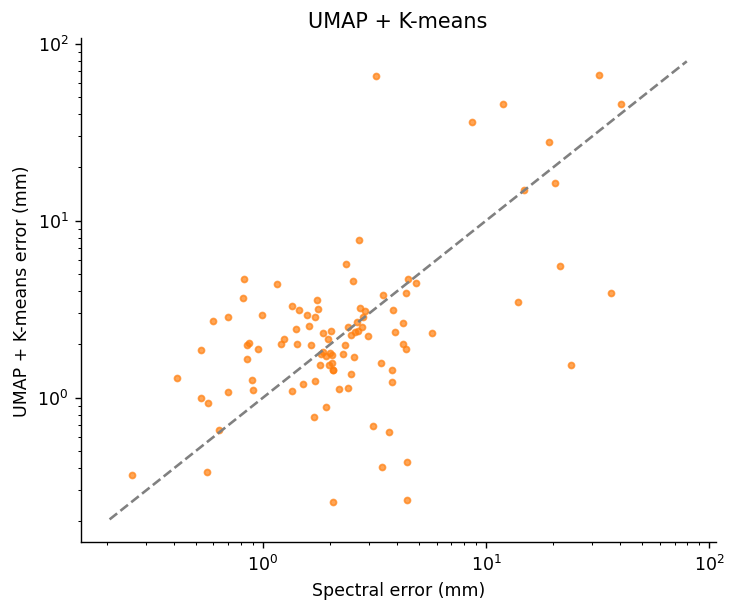

In [3]:
paired=[]
base=frames.get('spectral')
fig,ax=plt.subplots(figsize=(6,5))
for ax,m in [(ax,'umap')]:
    ax.set_title(METHODS[m]['label'])
    if base is None or m not in frames:
        ax.text(.5,.5,'Method unavailable',ha='center');continue
    f=frames[m];common=base.index.intersection(f.index)
    a=base.loc[common];b=f.loc[common]
    sa=a.success_30 & a.success_100;sb=b.success_30 & b.success_100
    only_a=int((sa & ~sb).sum());only_b=int((~sa & sb).sum());discordant=only_a+only_b
    paired.append({'method':m,'reference_method':'spectral','paired_seeds':len(common),'spectral_only':only_a,'umap_only':only_b,
        'both_success':int((sa&sb).sum()),'both_failure':int((~sa&~sb).sum()),
        'median_paired_error_change_mm':float(1000*(b.mean_last_100-a.mean_last_100).median()),
        'McNemar_exact_unadjusted_p':float(binomtest(only_b,discordant).pvalue) if discordant else 1.0})
    x=1000*a.mean_last_100;y=1000*b.mean_last_100
    ax.scatter(x,y,s=12,alpha=.7,color=colors[m]);lo=max(min(x.min(),y.min())*.8,1e-5);hi=max(x.max(),y.max())*1.2
    ax.plot([lo,hi],[lo,hi],color='gray',linestyle='--');ax.set(xscale='log',yscale='log',xlabel='Spectral error (mm)',ylabel='UMAP + K-means error (mm)')
display(pd.DataFrame(paired).round(4));save('paired_errors')


## Computation, chart health, and solver outcomes

mean_ms          median_ms             p99_ms  \
method                       spectral     umap  spectral     umap  spectral   
module                                                                        
Chart localization             0.8449   2.8441    0.7590   2.5445    1.9917   
Graph routing                  0.0084   0.0102    0.0070   0.0085    0.0307   
Linear subspace retrieval      0.0009   0.0009    0.0008   0.0008    0.0015   
Other control-loop work        0.0351   0.0352    0.0307   0.0305    0.1130   
QP construction and solve     36.5657  36.8268   33.6970  33.2555   99.2443   
Terminal-reference selection   0.0182   0.0198    0.0163   0.0158    0.0623   
Total online control          37.4732  39.7370   34.5583  35.9077  100.6306   

                                        
method                            umap  
module                                  
Chart localization              6.3042  
Graph routing                   0.0366  
Linear subspace retrieval       0.0017  
Other control-loop work         0.1168  
QP construction and solve      99.8270  
Terminal-reference selection    0.0583  
Total online control          104.9661

,fit_and_atlas_s,basis_cache_s,min_chart_size,max_chart_size,min_behavioral_numerical_rank,controller_basis_rank,weak_components,strong_components,directed_edges,gate_converged
method,,,,,,,,,,
spectral,1.1076,0.1525,466,1387,144,60,1,1,302,not applicable
umap,102.0507,0.1239,423,1516,144,60,1,1,311,not applicable


,spectral,umap
Solver status,,
optimal,32000,32000


One-time terminal-candidate setup per rollout (ms), outside online loop:


,mean,median,p95
spectral,5.7893,5.1987,8.8252
umap,5.8483,5.1087,9.1774


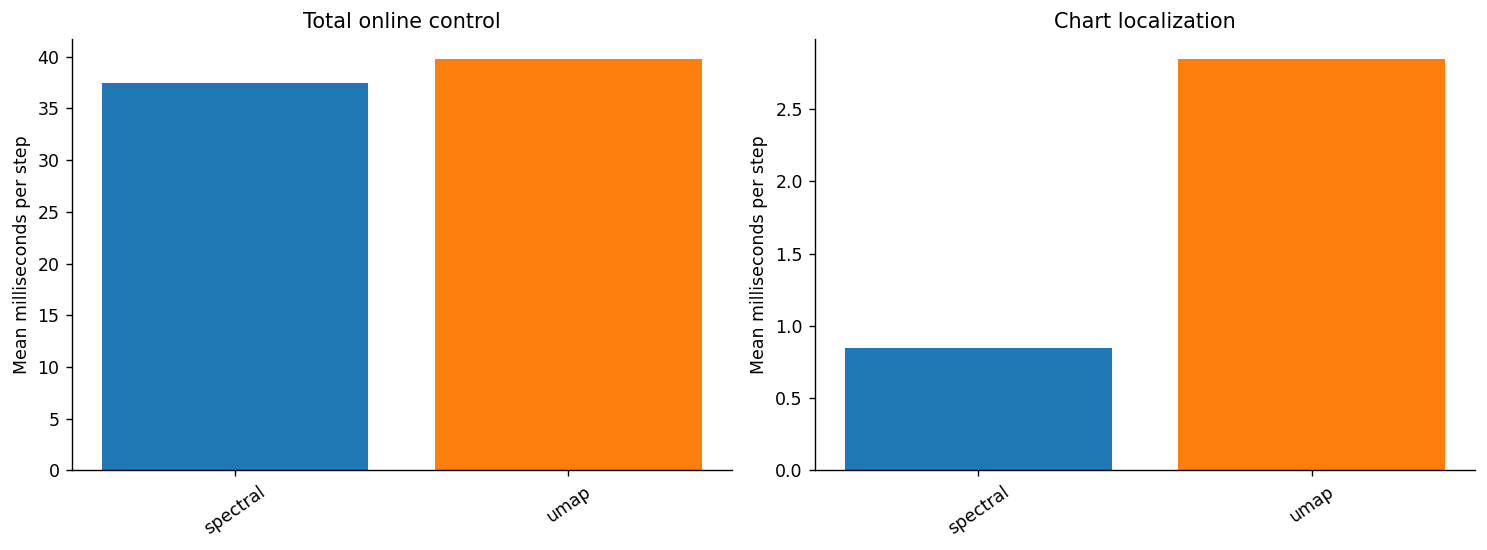

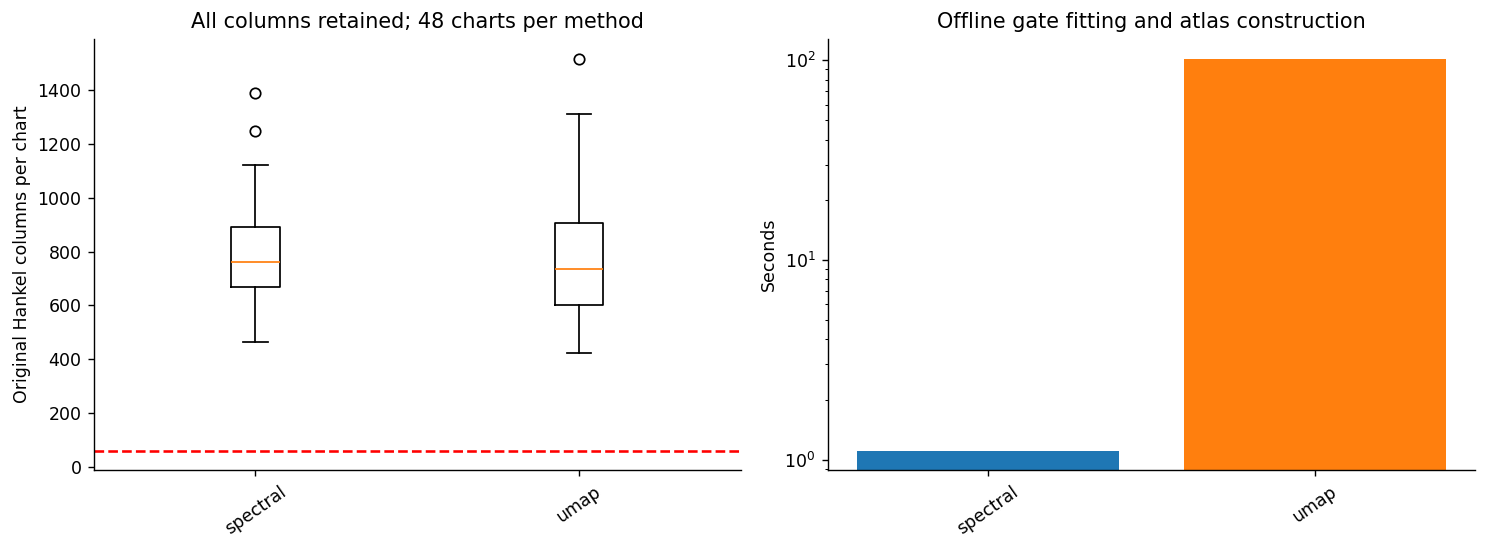

In [4]:
timing=[];offline=[];statuses={}
for m,p in panels.items():
    if p['timing']:
        assert p['timing']['timed_steps']==315*len(p['results'])
        timing += [{'method':m,**item} for item in p['timing']['modules']]
    meta=p['offline'];health=meta['health']
    offline.append({'method':m,'fit_and_atlas_s':meta['fit_and_atlas_seconds'],'basis_cache_s':meta['basis_cache_seconds'],
        'min_chart_size':min(health['chart_sizes']),'max_chart_size':max(health['chart_sizes']),
        'min_behavioral_numerical_rank':min(health['numerical_ranks']),'controller_basis_rank':60,
        'weak_components':health['weak_components'],'strong_components':health['strong_components'],
        'directed_edges':health['directed_edges'],'gate_converged':meta['gate_diagnostics'].get('converged','not applicable')})
    statuses[m]=dict(sum((Counter(r['statuses']) for r in p['results']),Counter()))
    assert sum(statuses[m].values())==320*len(p['results'])
timing=pd.DataFrame(timing)
display(timing.pivot(index='module',columns='method',values=['mean_ms','median_ms','p99_ms']).round(4))
display(pd.DataFrame(offline).set_index('method').round(4))
display(pd.DataFrame(statuses).fillna(0).astype(int).rename_axis('Solver status'))
print('One-time terminal-candidate setup per rollout (ms), outside online loop:')
display(pd.DataFrame({m:p['timing']['one_time_goal_setup_ms'] for m,p in panels.items() if p['timing']}).T.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,module in zip(axes,['Total online control','Chart localization']):
    t=timing[timing.module==module].set_index('method')
    names=[m for m in order if m in t.index]
    ax.bar(range(len(names)),t.loc[names].mean_ms,color=[colors[m] for m in names])
    ax.set(xticks=range(len(names)),xticklabels=names,ylabel='Mean milliseconds per step',title=module)
    ax.tick_params(axis='x',rotation=35)
save('online_timing')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
names=[m for m in order if m in panels]
axes[0].boxplot([panels[m]['offline']['health']['chart_sizes'] for m in names],tick_labels=names)
axes[0].axhline(61,color='red',linestyle='--');axes[0].set(ylabel='Original Hankel columns per chart',title='All columns retained; 48 charts per method')
axes[1].bar(names,[panels[m]['offline']['fit_and_atlas_seconds'] for m in names],color=[colors[m] for m in names])
axes[1].set(ylabel='Seconds',title='Offline gate fitting and atlas construction',yscale='log')
for ax in axes: ax.tick_params(axis='x',rotation=35)
save('offline_diagnostics')


## Physical robot-arm configurations by chart

Each method has a separate 6×8 grid covering all 48 charts. Each panel shows 32 reproducibly sampled member poses as transparent two-link arms and the saved medoid as a bold arm. The base is at the origin; the elbow uses the baseline 0.10 m first-link geometry and the fingertip uses the recorded physical position. All panels share the same scale. Titles show the full chart support, not the number of displayed poses. Chart IDs and colors are local to each method and do not imply matched clusters. These are physical poses, not embedding coordinates. PNG and PDF copies and sampled original-column indices are saved under `spectral_umap_report/`.

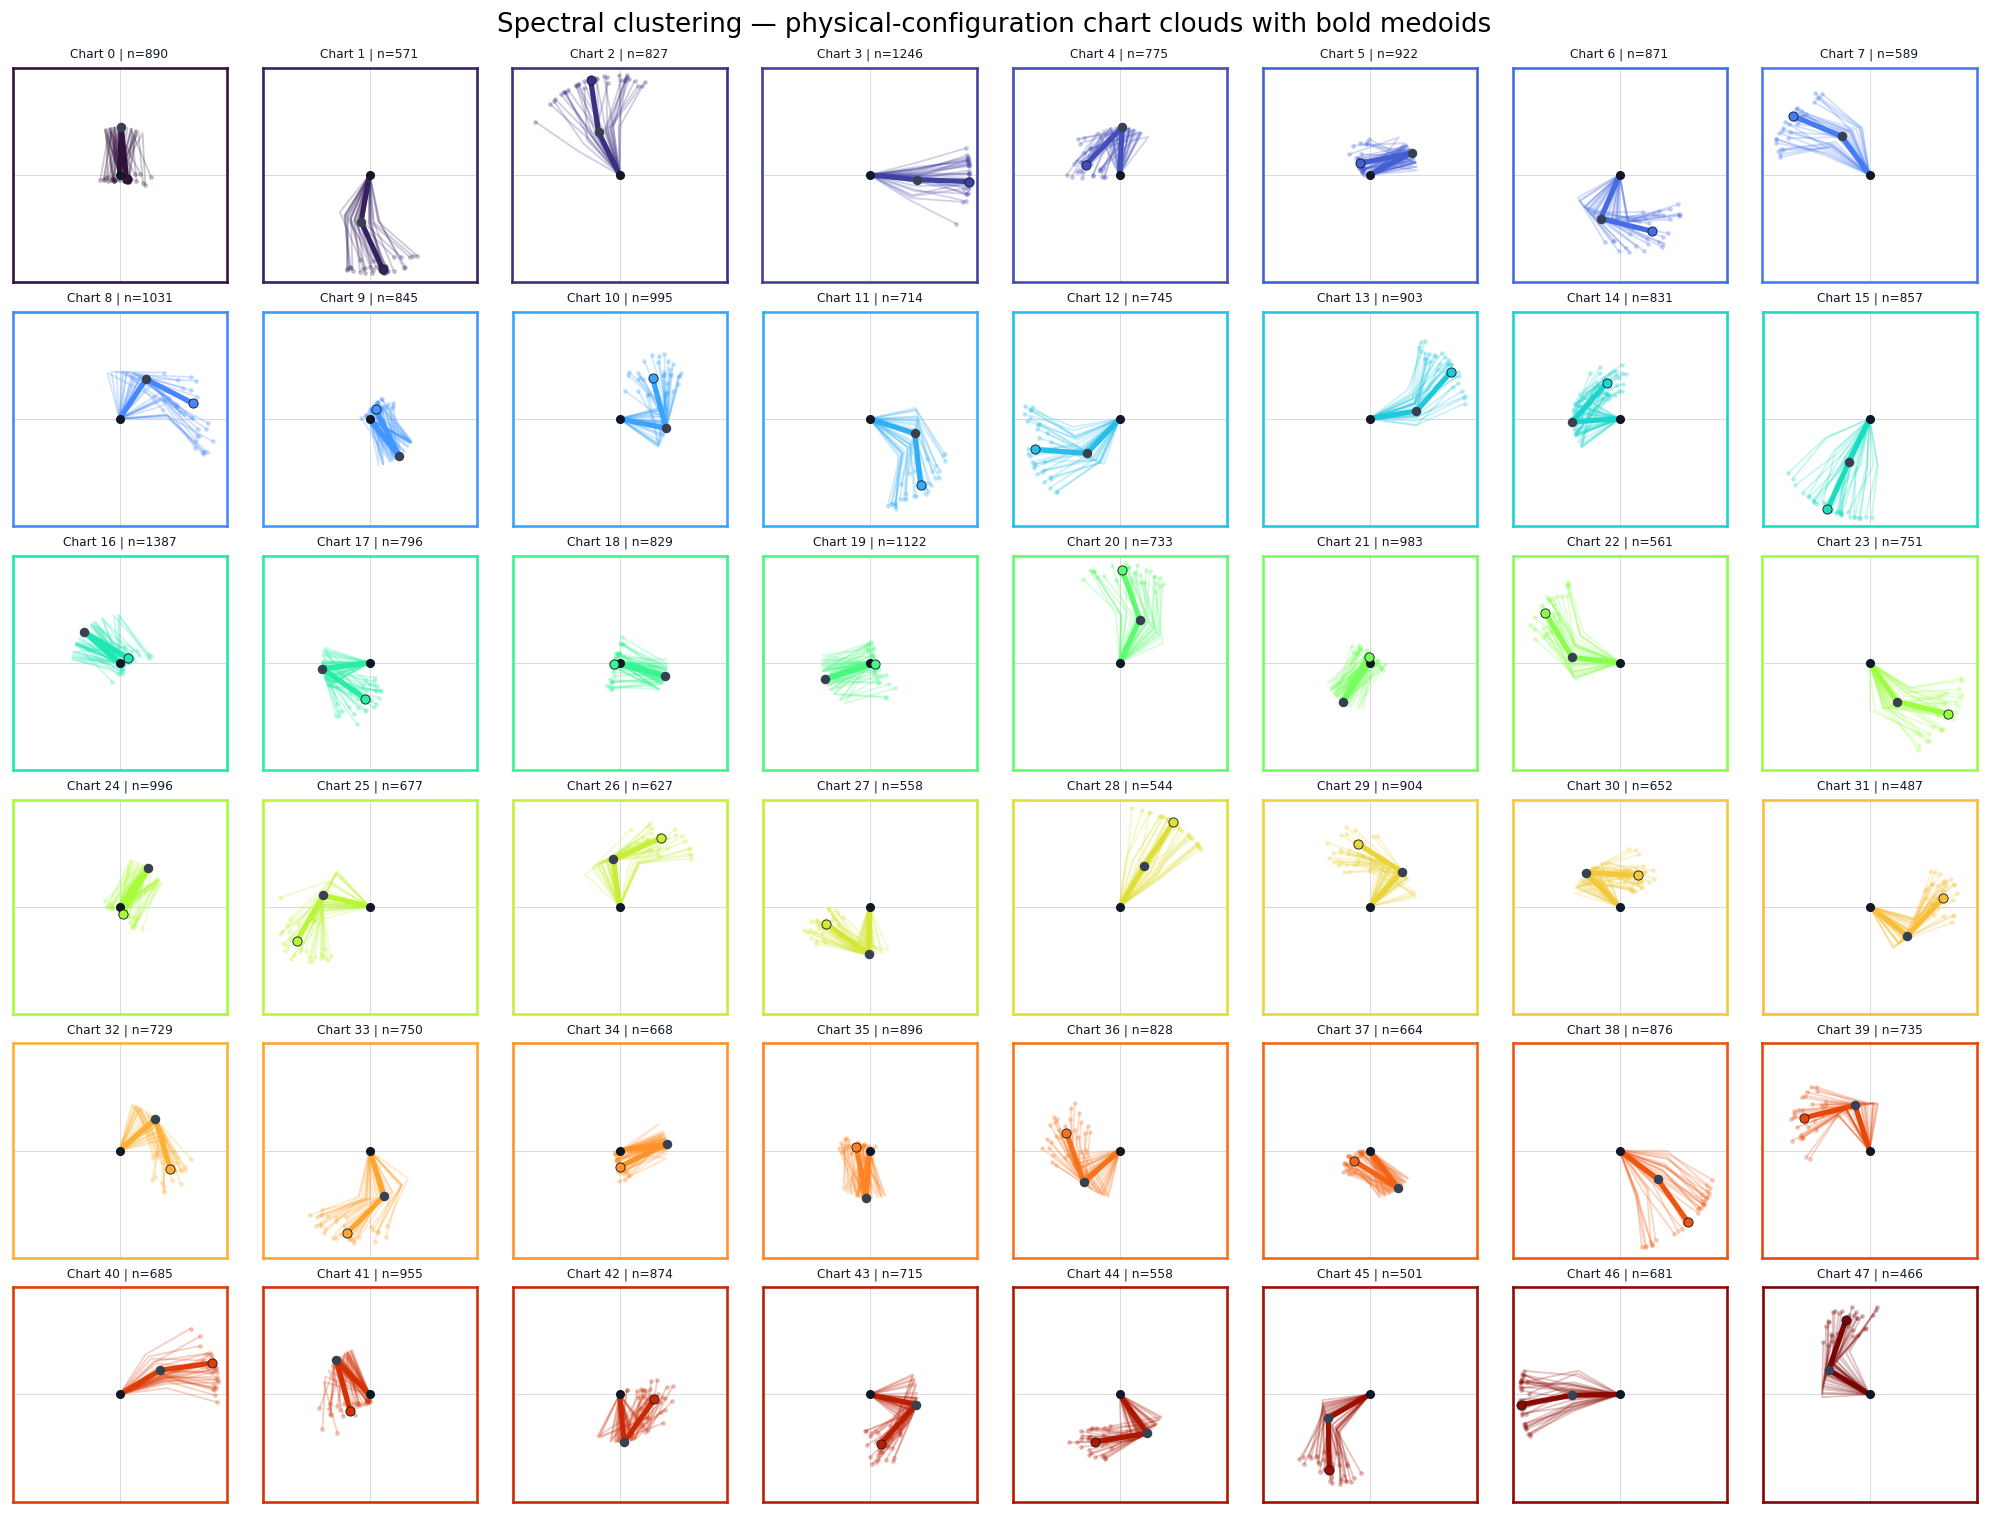

spectral: all 48 charts, 37,800 original columns; support 466–1387; max medoid FK discrepancy 0.570 mm


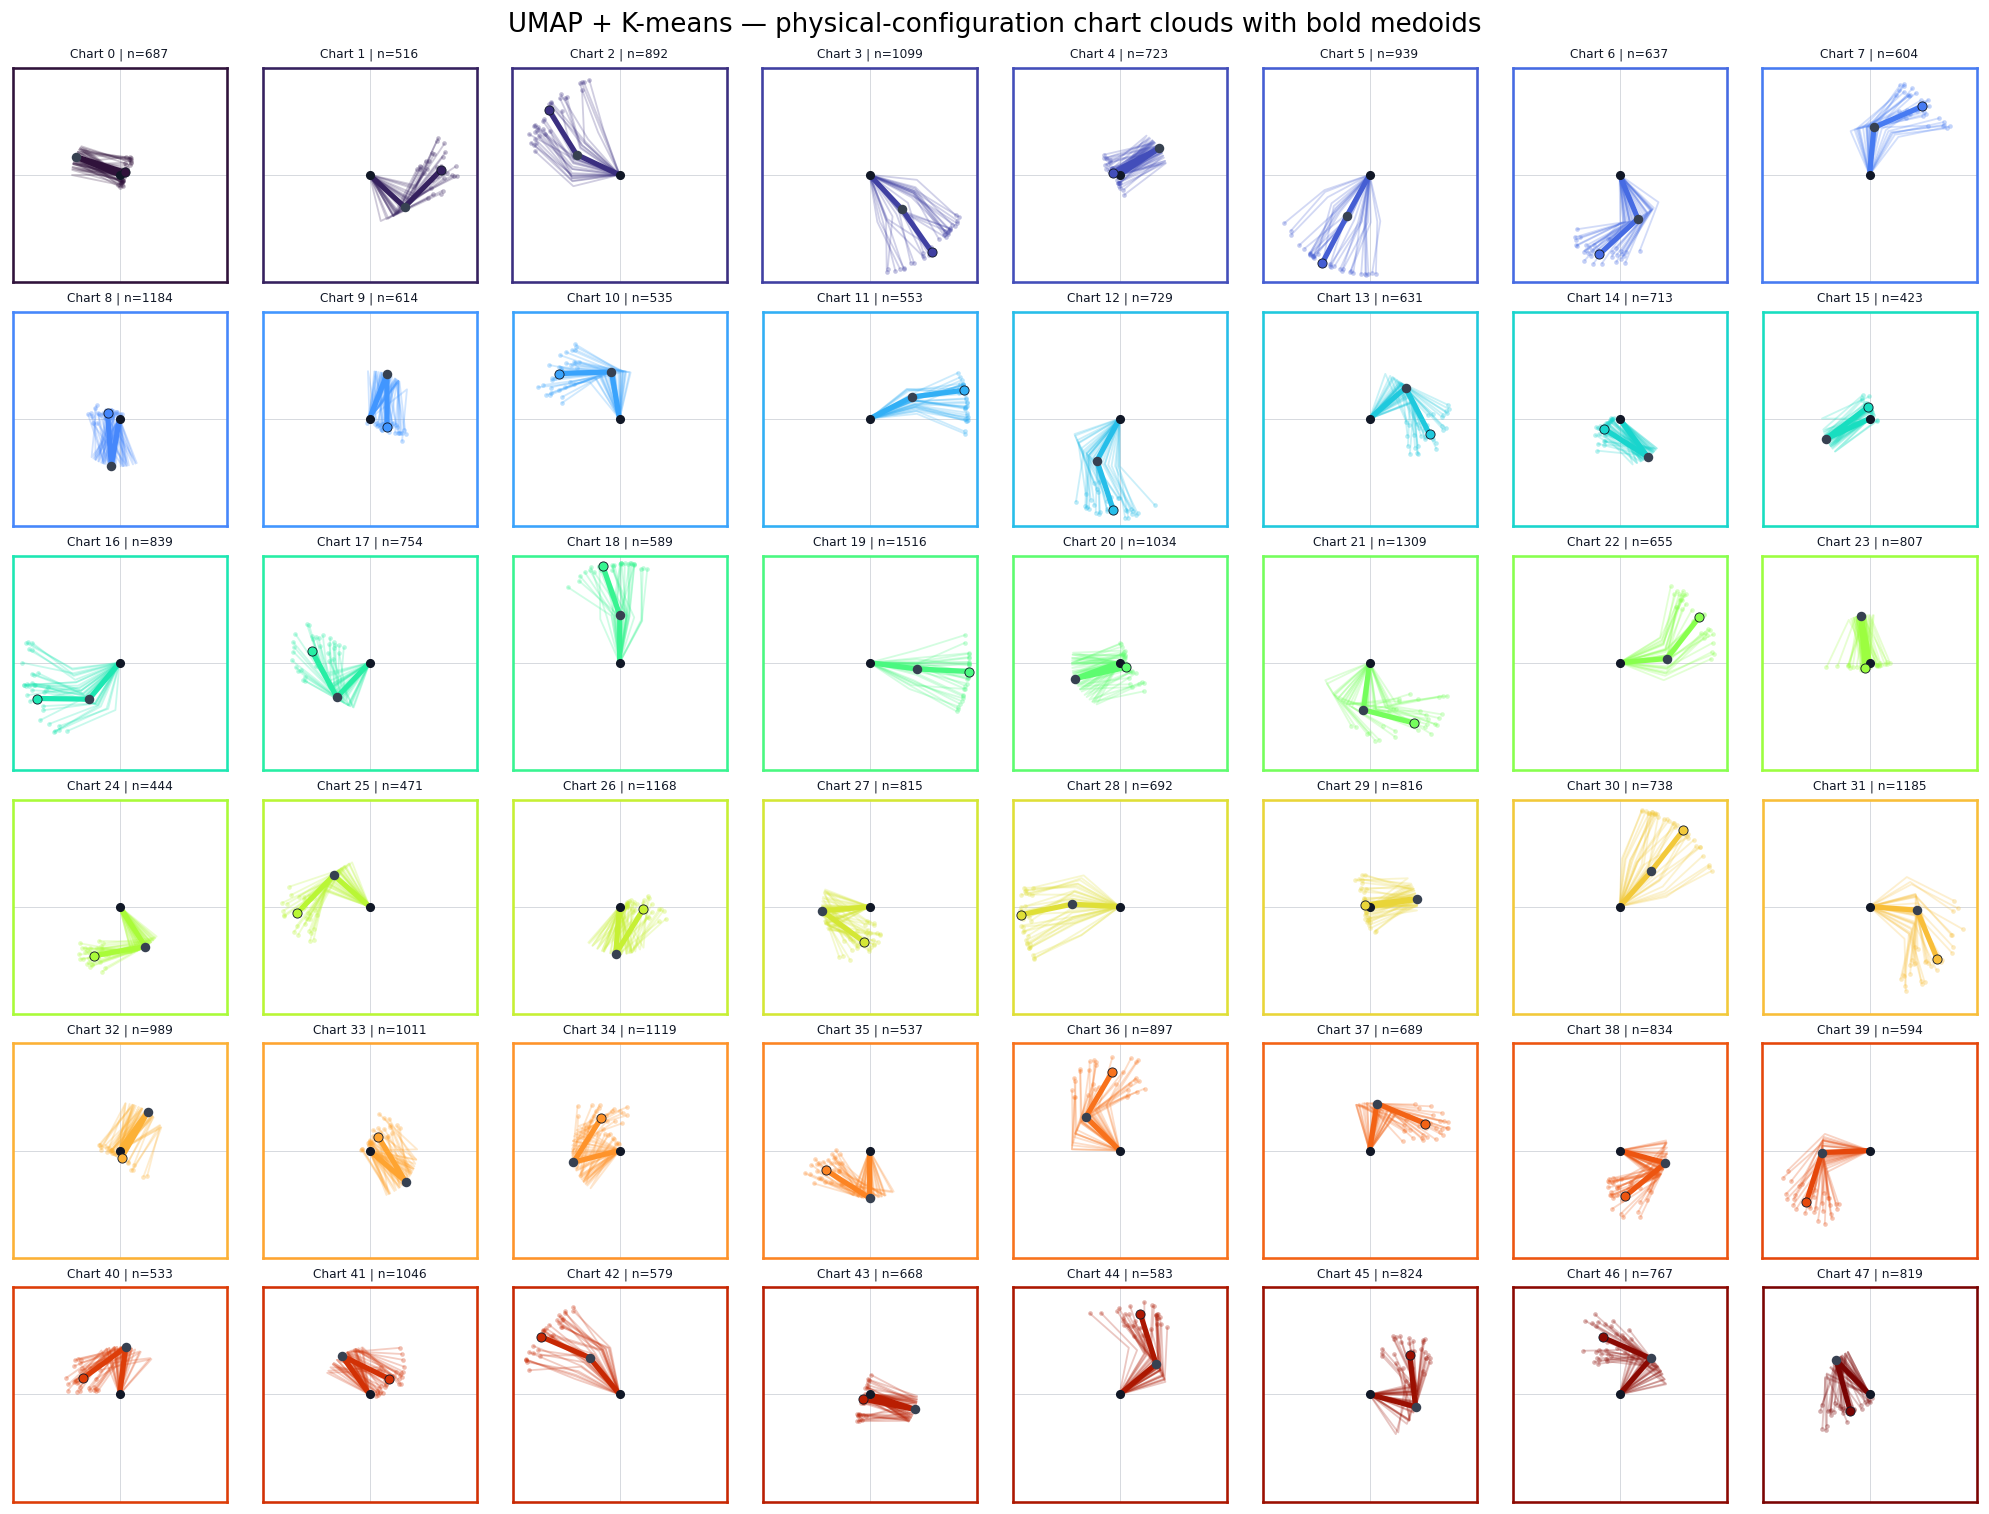

umap: all 48 charts, 37,800 original columns; support 423–1516; max medoid FK discrepancy 2.657 mm
Report saved. Interpret this as an exploratory comparison with fixed pre-evaluation settings.


In [5]:
from matplotlib.collections import LineCollection
H=np.load(experiment.DATA,mmap_mode='r')
Y=H[experiment.routed.pipe.M*experiment.routed.pipe.L:].reshape(experiment.routed.pipe.L,10,H.shape[1])[experiment.routed.pipe.T_INI-1].T
chart_colors=plt.cm.turbo(np.linspace(0,1,48))
pose_samples={}
for m in order:
    with np.load(R/m/'memberships.npz') as a:
        np.testing.assert_array_equal(a['column_indices'],np.arange(H.shape[1]))
        labels=a['labels'].copy()
        assert len(labels)==H.shape[1] and set(labels)==set(range(48))
        for k in range(48): np.testing.assert_array_equal(a[f'chart_{k:02d}'],np.flatnonzero(labels==k))
    with np.load(R/m/'atlas.npz') as a:
        np.testing.assert_array_equal(labels,a['labels'])
        medoids=a['medoid_states'].copy(); indices=a['medoid_indices'].copy()
    np.testing.assert_array_equal(labels[indices],np.arange(48))
    # Medoid velocities are zeroed in the atlas; pose channels retain the actual member values.
    np.testing.assert_array_equal(medoids[:,[0,1,2,3,6,7,8,9]],Y[indices][:,[0,1,2,3,6,7,8,9]])
    sizes=np.bincount(labels,minlength=48)
    np.testing.assert_array_equal(sizes,panels[m]['offline']['health']['chart_sizes'])
    rng=np.random.default_rng(17); pose_samples[m]={}
    fig,axes=plt.subplots(6,8,figsize=(16,12),constrained_layout=True)
    for k,ax in enumerate(axes.flat):
        members=np.flatnonzero(labels==k)
        chosen=rng.choice(members,size=min(32,len(members)),replace=False)
        pose_samples[m][str(k)]=chosen.tolist()
        states=Y[chosen];color=chart_colors[k]
        elbows=.10*states[:,[0,2]];tips=states[:,6:8]
        segments=np.stack([np.zeros_like(elbows),elbows,tips],axis=1)
        ax.add_collection(LineCollection(segments,colors=[color],linewidths=1.05,alpha=.24,zorder=1))
        ax.scatter(tips[:,0],tips[:,1],s=7,color=color,alpha=.32,linewidth=0,zorder=1)
        elbow=.10*medoids[k,[0,2]];tip=medoids[k,6:8]
        ax.plot([0,elbow[0],tip[0]],[0,elbow[1],tip[1]],color=color,linewidth=3,solid_capstyle='round',zorder=3)
        ax.scatter([0],[0],s=18,color='#111827',zorder=3)
        ax.scatter([elbow[0]],[elbow[1]],s=20,color='#374151',zorder=3)
        ax.scatter([tip[0]],[tip[1]],s=28,color=color,edgecolor='#111827',linewidth=.5,zorder=4)
        ax.axhline(0,color='#d1d5db',linewidth=.5,zorder=0)
        ax.axvline(0,color='#d1d5db',linewidth=.5,zorder=0)
        ax.set(xlim=(-.225,.225),ylim=(-.225,.225),aspect='equal',xticks=[],yticks=[])
        ax.set_title(f'Chart {k} | n={sizes[k]}',fontsize=7,color='#111827')
        for spine in ax.spines.values():
            spine.set_visible(True);spine.set_color(color);spine.set_linewidth(1.5)
    fig.suptitle(METHODS[m]['label']+' — physical-configuration chart clouds with bold medoids',fontsize=15)
    fig.savefig(F/(m+'_physical48_chart_configuration_clouds.png'),dpi=160,bbox_inches='tight')
    fig.savefig(F/(m+'_physical48_chart_configuration_clouds.pdf'),bbox_inches='tight')
    plt.show()
    fk=.10*medoids[:,[0,2]]+.11*medoids[:,[8,9]]
    print(f'{m}: all 48 charts, {sizes.sum():,} original columns; support {sizes.min()}–{sizes.max()}; max medoid FK discrepancy {1000*np.linalg.norm(fk-medoids[:,6:8],axis=1).max():.3f} mm')
(REPORT/'pose_sample_indices.json').write_text(json.dumps(pose_samples,indent=2))
report={'complete':True,'methods':order,'rollouts':sum(len(f) for f in frames.values()),'all_methods_succeeded':all(len(frames[m])==100 and not panels[m]['trial_failures'] for m in order),
    'outcomes':table.reset_index().where(pd.notna(table.reset_index()),None).to_dict(orient='records'),
    'paired':paired,'timing':timing.to_dict(orient='records'),'offline':offline,'statuses':statuses,
    'offline_failures':summary['offline_failures'],'dataset_sha256':summary['data_hash_final'],
    'figures':[str(p) for p in sorted(F.glob('*.png'))]}
(REPORT/'notebook_report.json').write_text(json.dumps(report,indent=2))
print('Report saved. Interpret this as an exploratory comparison with fixed pre-evaluation settings.')


## Observed comparison and limits

| Method | Success | Median error (mm) | Mean / median / P99 time (ms) |
|---|---:|---:|---:|
| spectral | 90/100 | 2.063 | 37.47 / 34.56 / 100.63 |
| umap | 92/100 | 2.089 | 39.74 / 35.91 / 104.97 |

UMAP succeeds on 92/100 seeds and spectral clustering on 90/100. Spectral has lower observed mean online time (37.47 versus 39.74 ms); its mean localization time is 0.845 ms versus 2.844 ms for UMAP. These are descriptive results on a reused exploratory panel, not evidence of a general ordering of the algorithm families.

All 64,000 QPs in these two methods are optimal. Both atlases have 48 nonempty charts, full numerical behavioral rank 144 before truncation, rank-60 controller bases, and a strongly connected directed transition graph. Spectral chart supports range from 466 to 1,387 original columns; UMAP supports range from 423 to 1,516. Observed unsuccessful rollouts are not explained by unsolved QPs, empty charts, or disconnected routing graphs.

Both methods use 1,500-landmark approximations with all 37,800 original columns assigned to charts. No hyperparameters were retuned against evaluation results. Selecting these two methods after the broader study does not make this an independent validation panel. Wall-clock timing can reflect shared-computer load; offline preparation includes the overheads described above. The full seven-method report and its original outputs remain archived separately.
